In [1]:
import numpy as np
import tensorflow as tf
import os

DATA_PATH = "../dataset/training"

# Load balanced dataset
X_train = np.load(os.path.join(DATA_PATH, "X_train.npy"))
X_test  = np.load(os.path.join(DATA_PATH, "X_test.npy"))
y_test  = np.load(os.path.join(DATA_PATH, "y_test.npy"))

# Normalize using training statistics
train_mean = X_train.mean(axis=(0,1), keepdims=True)
train_std  = X_train.std(axis=(0,1), keepdims=True) + 1e-8

X_test = (X_test - train_mean) / train_std

# ⭐ Load the trained Transformer V4.1 model
model = tf.keras.models.load_model("../models/best_transformer_v4_1.keras")

print("✅ Test set normalized.")
print("✅ V4.1 model loaded successfully.")

KeyboardInterrupt: 

In [12]:
predictions = model.predict(X_test, verbose=0)
y_pred = np.argmax(predictions, axis=1)

acc = np.mean(y_pred == y_test)

print("Manual Accuracy:", acc)
print("Predictions as class 76:", np.sum(y_pred == 76))
print("Unique predicted classes:", len(np.unique(y_pred)))

Manual Accuracy: 0.8261904761904761
Predictions as class 76: 0
Unique predicted classes: 202


In [13]:
# ===== MODEL SANITY CHECK =====

print("Output shape :", model.output_shape)
print("Last layer   :", model.layers[-1].name)
print("Units in last layer :", model.layers[-1].units)

print("\nModel summary (last 5 layers):")
for layer in model.layers[-5:]:
    print(layer.name, layer.output_shape)

Output shape : (None, 210)
Last layer   : dense_6
Units in last layer : 210

Model summary (last 5 layers):


AttributeError: 'GlobalAveragePooling1D' object has no attribute 'output_shape'

In [14]:
predictions = model.predict(X_test, verbose=0)
y_pred = predictions.argmax(axis=1)

manual_acc = (y_pred == y_test).mean()

print("Manual Accuracy:", manual_acc)
print("Predictions as class 76:", (y_pred == 76).sum())
print("Unique predicted classes:", len(set(y_pred)))

Manual Accuracy: 0.8261904761904761
Predictions as class 76: 0
Unique predicted classes: 202


In [15]:
# ============================================
# Predict Test Dataset
# ============================================

predictions = model.predict(X_test, verbose=1)

y_pred = np.argmax(predictions, axis=1)

print("Prediction Shape :", predictions.shape)
print("Predicted Labels :", y_pred.shape)

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step
Prediction Shape : (420, 210)
Predicted Labels : (420,)


In [16]:
# ============================================
# Classification Report
# ============================================

from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print(report_df.head())

os.makedirs("../outputs", exist_ok=True)
report_df.to_csv("../outputs/classification_report_v4_1.csv")

print("✅ classification_report_v4_1.csv saved!")

   precision  recall  f1-score  support
0        1.0     1.0       1.0      2.0
1        1.0     1.0       1.0      2.0
2        1.0     1.0       1.0      2.0
3        1.0     1.0       1.0      2.0
4        1.0     1.0       1.0      2.0
✅ classification_report_v4_1.csv saved!


In [17]:
# ============================================
# Refresh predictions from the loaded V4.1 model
# ============================================

predictions = model.predict(X_test, verbose=0)
y_pred = np.argmax(predictions, axis=1)

print("Unique predicted classes :", len(np.unique(y_pred)))
print("Predictions as class 76  :", np.sum(y_pred == 76))

# Sanity check accuracy
acc = np.mean(y_pred == y_test)
print("Accuracy from y_pred      :", acc)

Unique predicted classes : 202
Predictions as class 76  : 0
Accuracy from y_pred      : 0.8261904761904761


In [18]:
print("y_test shape :", y_test.shape)
print("y_test dtype :", y_test.dtype)

print("\nFirst 10 labels:")
print(y_test[:10])

print("\nUnique labels:", len(np.unique(y_test)))
print("Min label:", np.min(y_test))
print("Max label:", np.max(y_test))

y_test shape : (420,)
y_test dtype : int32

First 10 labels:
[189 110  99 157  85 127 191 173 151 140]

Unique labels: 210
Min label: 0
Max label: 209


In [19]:
# Manual evaluation check
loss, acc = model.evaluate(X_test, y_test, verbose=0)

pred = model.predict(X_test, verbose=0)
pred_labels = np.argmax(pred, axis=1)

manual_acc = np.mean(pred_labels == y_test)

print("model.evaluate accuracy :", acc)
print("manual accuracy         :", manual_acc)

model.evaluate accuracy : 0.8261904716491699
manual accuracy         : 0.8261904761904761


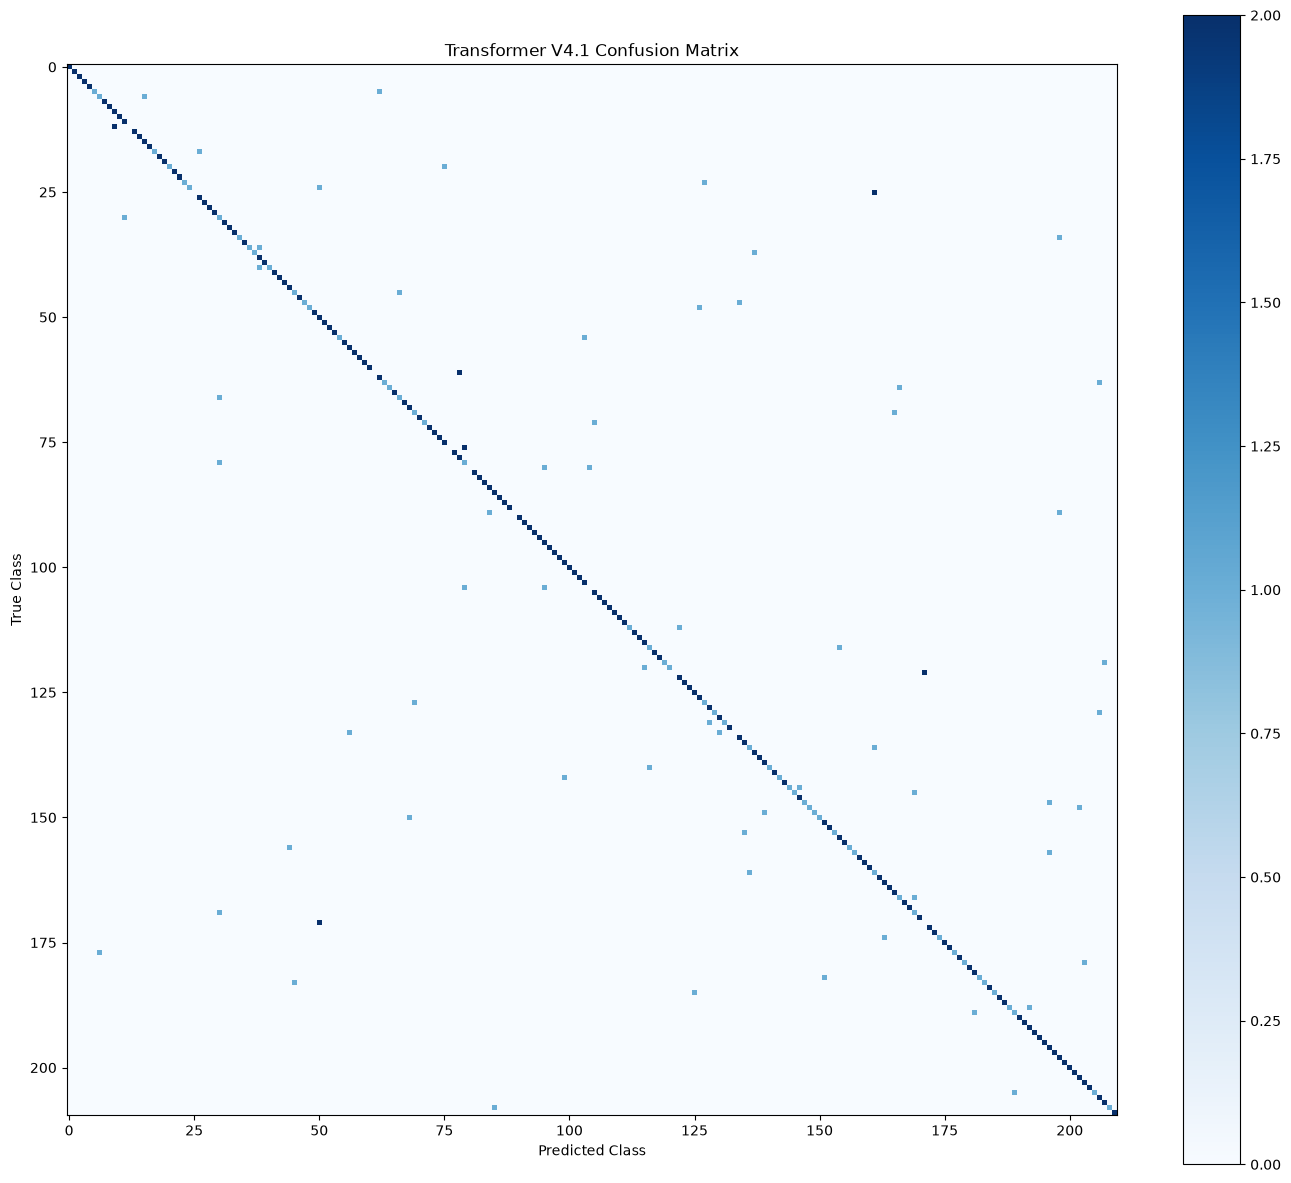

In [20]:
# ============================================
# Confusion Matrix
# ============================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14,12))

plt.imshow(cm, interpolation="nearest", cmap="Blues")

plt.title("Transformer V4.1 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.colorbar()

plt.tight_layout()
plt.show()


In [21]:
# ============================================
# Top 15 Most Confused Gesture Pairs
# ============================================

cm_copy = cm.copy()

np.fill_diagonal(cm_copy, 0)

pairs = []

for i in range(cm_copy.shape[0]):
    for j in range(cm_copy.shape[1]):
        if cm_copy[i, j] > 0:
            pairs.append((i, j, cm_copy[i, j]))

pairs = sorted(pairs, key=lambda x: x[2], reverse=True)

top_pairs = pd.DataFrame(
    pairs[:15],
    columns=["True Gesture", "Predicted Gesture", "Mistakes"]
)

print(top_pairs)

top_pairs.to_csv("../outputs/top15_confused_pairs.csv", index=False)

print("✅ top15_confused_pairs.csv saved!")

    True Gesture  Predicted Gesture  Mistakes
0             12                  9         2
1             25                161         2
2             61                 78         2
3             76                 79         2
4            121                171         2
5            171                 50         2
6              5                 62         1
7              6                 15         1
8             17                 26         1
9             20                 75         1
10            23                127         1
11            24                 50         1
12            30                 11         1
13            34                198         1
14            36                 38         1
✅ top15_confused_pairs.csv saved!


In [22]:
# ============================================
# Per-Class Accuracy
# ============================================

class_accuracy = []

for cls in range(210):
    idx = np.where(y_test == cls)[0]

    correct = np.sum(y_pred[idx] == y_test[idx])

    acc = correct / len(idx)

    class_accuracy.append((cls, acc, len(idx)))

class_acc_df = pd.DataFrame(
    class_accuracy,
    columns=["Gesture", "Accuracy", "Samples"]
)

class_acc_df = class_acc_df.sort_values("Accuracy")

print(class_acc_df.head(20))

class_acc_df.to_csv("../outputs/class_accuracy_v4_1.csv", index=False)

print("✅ class_accuracy_v4_1.csv saved!")

     Gesture  Accuracy  Samples
104      104       0.0        2
171      171       0.0        2
61        61       0.0        2
25        25       0.0        2
76        76       0.0        2
89        89       0.0        2
12        12       0.0        2
133      133       0.0        2
80        80       0.0        2
121      121       0.0        2
136      136       0.5        2
47        47       0.5        2
48        48       0.5        2
174      174       0.5        2
54        54       0.5        2
169      169       0.5        2
120      120       0.5        2
116      116       0.5        2
63        63       0.5        2
64        64       0.5        2
✅ class_accuracy_v4_1.csv saved!


In [23]:
# ============================================
# Analyze Gesture 76
# ============================================

target = 76

# All samples predicted as 76
predicted_as_target = np.where(y_pred == target)[0]

print(f"Total predictions as Gesture {target}: {len(predicted_as_target)}\n")

for idx in predicted_as_target:
    print(
        f"Sample {idx} | True: {y_test[idx]} | Predicted: {y_pred[idx]}"
    )

Total predictions as Gesture 76: 0



In [24]:
# ============================================
# Precision / Recall for Gesture 76
# ============================================

gesture = 76

true_mask = (y_test == gesture)
pred_mask = (y_pred == gesture)

print("Actual Gesture 76 samples:", np.sum(true_mask))
print("Predicted as Gesture 76 :", np.sum(pred_mask))
print("Correct Gesture 76      :", np.sum(true_mask & pred_mask))

Actual Gesture 76 samples: 2
Predicted as Gesture 76 : 0
Correct Gesture 76      : 0


In [25]:
# ============================================
# Check Dataset Frequency for Class 76
# ============================================

import os
import numpy as np

DATA_PATH = "../dataset/training"

# Load labels for all splits
y_train = np.load(os.path.join(DATA_PATH, "y_train.npy"))
y_val   = np.load(os.path.join(DATA_PATH, "y_val.npy"))
y_test  = np.load(os.path.join(DATA_PATH, "y_test.npy"))

train_counts = np.bincount(y_train, minlength=210)
val_counts   = np.bincount(y_val, minlength=210)
test_counts  = np.bincount(y_test, minlength=210)

print("📊 Class 76 Counts")
print("-------------------")
print("Train :", train_counts[76])
print("Val   :", val_counts[76])
print("Test  :", test_counts[76])

print("\n🏆 Top 10 Most Frequent Training Classes")

top10 = np.argsort(train_counts)[::-1][:10]

for cls in top10:
    print(f"Class {cls:3d} : {train_counts[cls]} samples")

📊 Class 76 Counts
-------------------
Train : 44
Val   : 3
Test  : 2

🏆 Top 10 Most Frequent Training Classes
Class  93 : 51 samples
Class  92 : 48 samples
Class 159 : 48 samples
Class 181 : 48 samples
Class 178 : 48 samples
Class 175 : 48 samples
Class 172 : 48 samples
Class 103 : 48 samples
Class 169 : 48 samples
Class 208 : 48 samples


In [26]:
# ============================================
# Confidence of Predictions
# ============================================

confidence = np.max(predictions, axis=1)

print("Average confidence:", confidence.mean())
print("Minimum confidence:", confidence.min())
print("Maximum confidence:", confidence.max())

pred76 = np.where(y_pred == 76)[0]

print("\nAverage confidence when predicting 76:",
      confidence[pred76].mean())

print("Highest 10 confidences for class 76:")
print(np.sort(confidence[pred76])[-10:])

Average confidence: 0.8671657
Minimum confidence: 0.28683397
Maximum confidence: 0.9999951

Average confidence when predicting 76: nan
Highest 10 confidences for class 76:
[]


C:\Users\palak\AppData\Local\Temp\ipykernel_21852\2264495460.py:14: RuntimeWarning: Mean of empty slice.
  confidence[pred76].mean())
c:\Users\palak\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


In [27]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv("../outputs/classification_report_v4_1.csv")

print("✅ Classification report saved.")
print(report_df.head(10))

✅ Classification report saved.
   precision  recall  f1-score  support
0        1.0     1.0  1.000000      2.0
1        1.0     1.0  1.000000      2.0
2        1.0     1.0  1.000000      2.0
3        1.0     1.0  1.000000      2.0
4        1.0     1.0  1.000000      2.0
5        1.0     0.5  0.666667      2.0
6        0.5     0.5  0.500000      2.0
7        1.0     1.0  1.000000      2.0
8        1.0     1.0  1.000000      2.0
9        0.5     1.0  0.666667      2.0


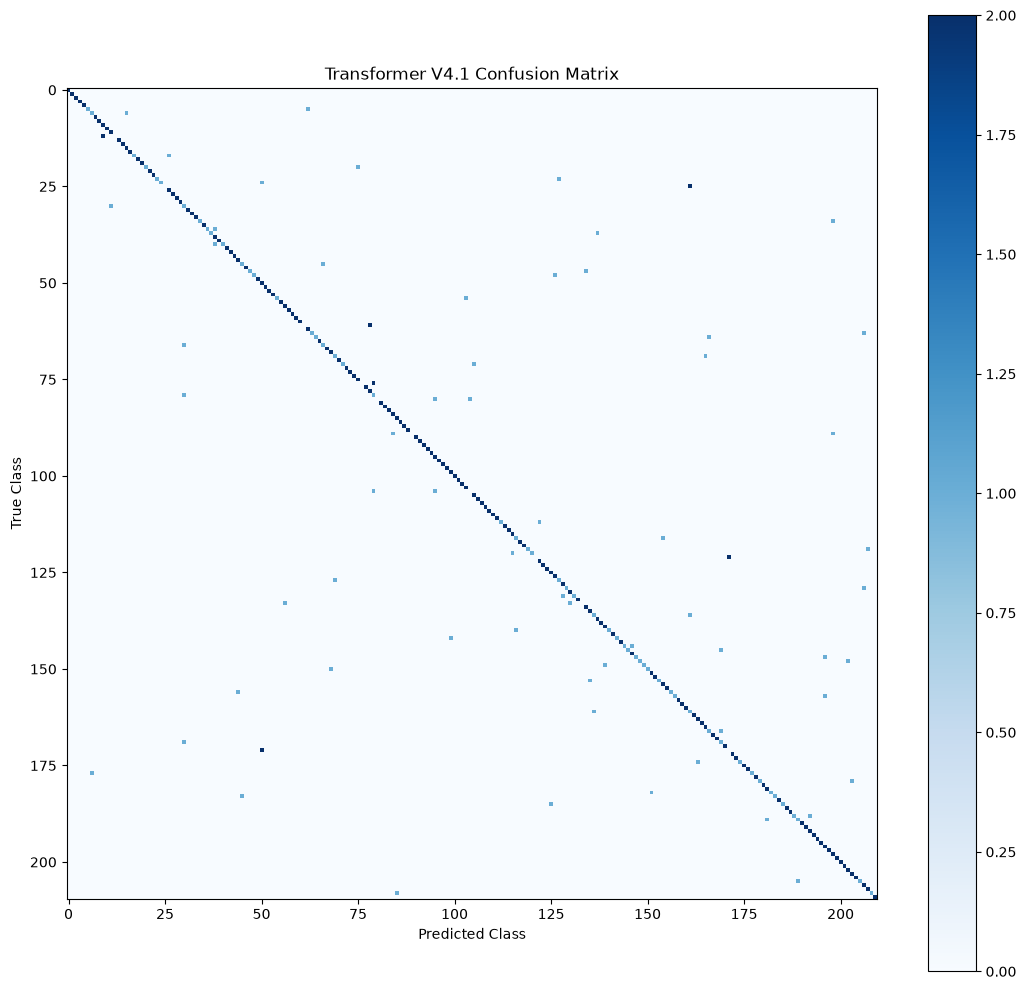

✅ Confusion matrix generated.


In [28]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(11,10))
plt.imshow(cm, cmap="Blues")
plt.title("Transformer V4.1 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.colorbar()
plt.tight_layout()
plt.show()

print("✅ Confusion matrix generated.")

In [29]:
import pandas as pd
import numpy as np

pairs = []

for true_class in range(210):
    for pred_class in range(210):
        if true_class != pred_class and cm[true_class, pred_class] > 0:
            pairs.append(
                [true_class, pred_class, cm[true_class, pred_class]]
            )

pairs_df = pd.DataFrame(
    pairs,
    columns=["True Gesture", "Predicted Gesture", "Mistakes"]
)

pairs_df = pairs_df.sort_values(
    "Mistakes",
    ascending=False
).head(15)

pairs_df.to_csv(
    "../outputs/top15_confused_pairs_v4_1.csv",
    index=False
)

print("✅ Top 15 confused pairs saved.")
print(pairs_df)

✅ Top 15 confused pairs saved.
    True Gesture  Predicted Gesture  Mistakes
35           121                171         2
2             12                  9         2
17            61                 78         2
23            76                 79         2
7             25                161         2
56           171                 50         2
44           144                146         1
48           149                139         1
47           148                202         1
46           147                196         1
45           145                169         1
43           142                 99         1
50           153                135         1
42           140                116         1
41           136                161         1


In [30]:
class_accuracy = []

for cls in range(210):
    mask = y_test == cls

    total = np.sum(mask)

    correct = np.sum((y_pred == cls) & mask)

    accuracy = correct / total if total else 0

    class_accuracy.append([cls, accuracy, total])

class_acc_df = pd.DataFrame(
    class_accuracy,
    columns=["Gesture", "Accuracy", "Samples"]
)

class_acc_df.to_csv(
    "../outputs/class_accuracy_v4_1.csv",
    index=False
)

print("✅ Per-class accuracy saved.")
print(class_acc_df.sort_values("Accuracy").head(20))

✅ Per-class accuracy saved.
     Gesture  Accuracy  Samples
104      104       0.0        2
171      171       0.0        2
61        61       0.0        2
25        25       0.0        2
76        76       0.0        2
89        89       0.0        2
12        12       0.0        2
133      133       0.0        2
80        80       0.0        2
121      121       0.0        2
136      136       0.5        2
47        47       0.5        2
48        48       0.5        2
174      174       0.5        2
54        54       0.5        2
169      169       0.5        2
120      120       0.5        2
116      116       0.5        2
63        63       0.5        2
64        64       0.5        2


In [ ]:
25/09/26

In [2]:
# ==========================================
# SanketSetu V5.2 - Model Analysis
# ==========================================

import os
import numpy as np
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

DATA_PATH = "../dataset/training"
OUTPUT_PATH = "../outputs"

os.makedirs(OUTPUT_PATH, exist_ok=True)

# Load datasets
X_train = np.load(os.path.join(DATA_PATH, "X_train.npy"))
X_test = np.load(os.path.join(DATA_PATH, "X_test.npy"))
y_test = np.load(os.path.join(DATA_PATH, "y_test.npy"))

print("✅ Dataset Loaded")
print("Train:", X_train.shape)
print("Test :", X_test.shape)
print("Classes:", len(np.unique(y_test)))

✅ Dataset Loaded
Train: (7320, 154, 63)
Test : (420, 154, 63)
Classes: 210


In [4]:
# ==========================================
# Load Best Transformer V5.2 Model
# ==========================================

MODEL_PATH = "../models/best_transformer_v5_2.keras"

model = load_model(MODEL_PATH)

print("✅ Transformer V5.2 loaded successfully!")
print("Output shape:", model.output_shape)
print("Last Layer:", model.layers[-1].name)

✅ Transformer V5.2 loaded successfully!
Output shape: (None, 210)
Last Layer: dense_6


In [5]:
# ==========================================
# Normalize Test Dataset
# ==========================================

train_mean = X_train.mean(axis=(0,1), keepdims=True)
train_std = X_train.std(axis=(0,1), keepdims=True) + 1e-8

X_test = (X_test - train_mean) / train_std

print("✅ Test set normalized!")

print("Mean :", round(float(X_test.mean()),4))
print("Std  :", round(float(X_test.std()),4))

✅ Test set normalized!
Mean : -0.0063
Std  : 0.9921


In [6]:
# ==========================================
# Prediction + Test Accuracy
# ==========================================

predictions = model.predict(X_test, verbose=0)

y_pred = np.argmax(predictions, axis=1)

test_accuracy = accuracy_score(y_test, y_pred)

print("🎯 Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Unique Predicted Classes:", len(np.unique(y_pred)))

🎯 Test Accuracy: 89.76 %
Unique Predicted Classes: 206


In [7]:
# ==========================================
# Classification Report
# ==========================================

report = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_path = os.path.join(
    OUTPUT_PATH,
    "classification_report_v5_2.csv"
)

report_df.to_csv(report_path)

print("✅ Classification report saved!")
print(report_df.head())

✅ Classification report saved!
   precision  recall  f1-score  support
0   1.000000     1.0       1.0      2.0
1   0.666667     1.0       0.8      2.0
2   1.000000     1.0       1.0      2.0
3   1.000000     1.0       1.0      2.0
4   1.000000     1.0       1.0      2.0


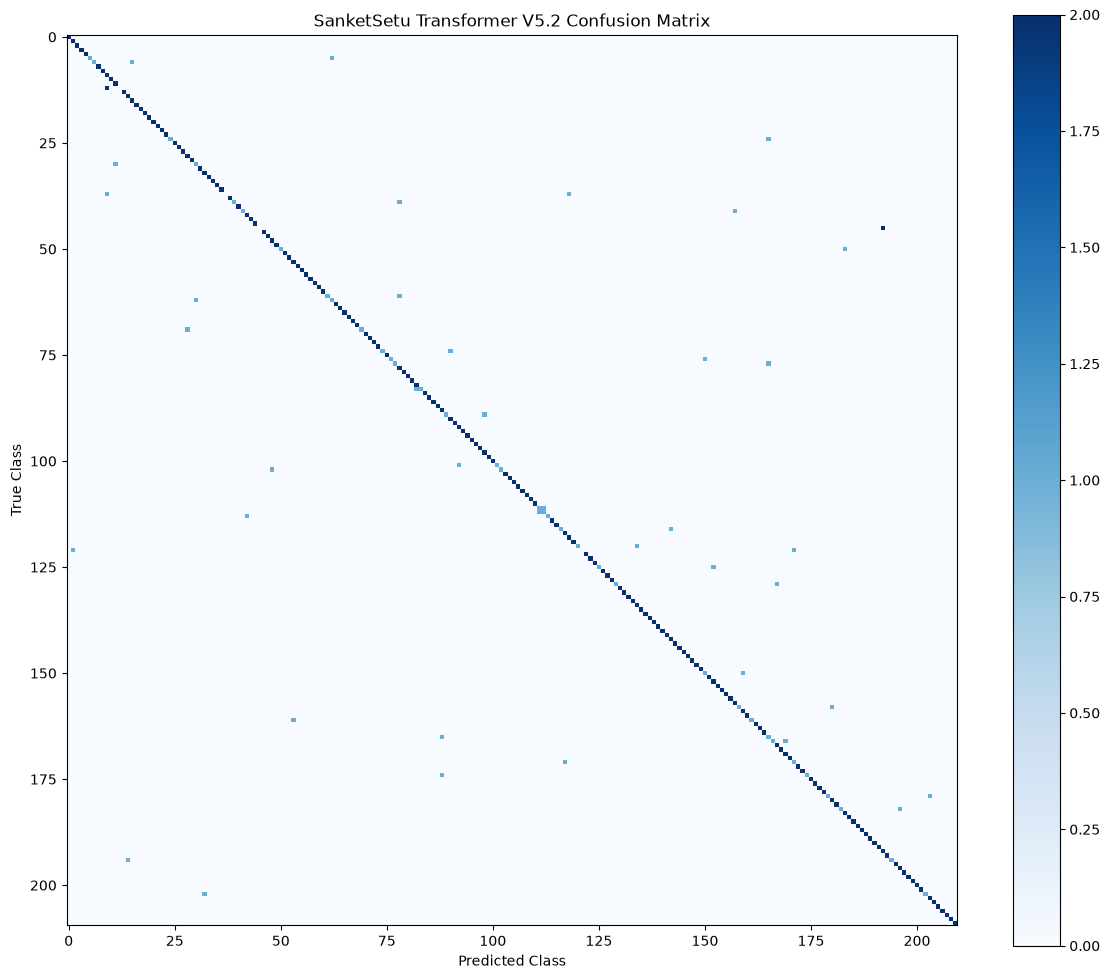

✅ Confusion Matrix saved!


In [8]:
# ==========================================
# Confusion Matrix
# ==========================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12,10))

plt.imshow(cm, cmap="Blues")

plt.title("SanketSetu Transformer V5.2 Confusion Matrix")

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.colorbar()

conf_path = os.path.join(
    OUTPUT_PATH,
    "confusion_matrix_v5_2.png"
)

plt.tight_layout()
plt.savefig(conf_path, dpi=300)
plt.show()

print("✅ Confusion Matrix saved!")

In [1]:
import os
import matplotlib.pyplot as plt

OUTPUT_DIR = "../outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save the confusion matrix currently on screen
plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix_v5_2.png"),
    dpi=300,
    bbox_inches="tight"
)

print("✅ Confusion matrix saved to outputs/confusion_matrix_v5_2.png")

✅ Confusion matrix saved to outputs/confusion_matrix_v5_2.png


<Figure size 640x480 with 0 Axes>

In [9]:
# ==========================================
# Per-Class Accuracy + Top Confusions
# ==========================================

class_accuracy = []

for cls in range(210):

    idx = np.where(y_test == cls)[0]

    if len(idx) == 0:
        continue

    acc = np.mean(y_pred[idx] == cls)

    class_accuracy.append({
        "Gesture": cls,
        "Accuracy": acc,
        "Samples": len(idx)
    })

class_accuracy_df = pd.DataFrame(class_accuracy)

class_accuracy_df.to_csv(
    os.path.join(OUTPUT_PATH, "class_accuracy_v5_2.csv"),
    index=False
)

print("✅ Per-class accuracy saved!")

# -------------------------
# Top confused pairs
# -------------------------

cm_no_diag = cm.copy()

np.fill_diagonal(cm_no_diag, 0)

pairs = []

for true_cls in range(cm_no_diag.shape[0]):
    for pred_cls in range(cm_no_diag.shape[1]):
        if cm_no_diag[true_cls, pred_cls] > 0:
            pairs.append([
                true_cls,
                pred_cls,
                cm_no_diag[true_cls, pred_cls]
            ])

pairs_df = pd.DataFrame(
    pairs,
    columns=["True Gesture", "Predicted Gesture", "Mistakes"]
)

pairs_df = pairs_df.sort_values(
    "Mistakes",
    ascending=False
).head(15)

pairs_df.to_csv(
    os.path.join(OUTPUT_PATH, "top15_confused_pairs_v5_2.csv"),
    index=False
)

print("✅ Top 15 confused pairs saved!")

display(pairs_df)

✅ Per-class accuracy saved!
✅ Top 15 confused pairs saved!


,True Gesture,Predicted Gesture,Mistakes
2,12,9,2
9,45,192,2
0,5,62,1
31,158,180,1
24,116,142,1
25,120,134,1
26,121,1,1
27,121,171,1
28,125,152,1
29,129,167,1
